# Carga del histórico de captaciones wifi en InfluxDB 2.x

Trabajo de Big Data Aplicado: captaciones wifi del aeropuerto (junio 2026).

**Flujo del notebook**
1. Cargar el CSV
2. Limpiar los datos (se descartan las filas incorrectas)
3. Transformar para InfluxDB (tags, fields, zona horaria, colisiones)
4. Subir a InfluxDB 2.x (bucket `captaciones_julio`)

> Por seguridad, la subida está **desactivada** por defecto (`SUBIR = False`). Revisa el informe de limpieza y activa la subida en la celda de la sección 4.

In [1]:
import os
import pandas as pd

# ---------------- CONFIGURACIÓN ----------------
CSV = "captaciones_junio_2026.csv"
RECHAZADAS = "captaciones_rechazadas.csv"

INFLUX_URL = os.environ.get("INFLUX_URL", "http://localhost:8086")
INFLUX_TOKEN = os.environ.get("INFLUX_TOKEN", "CAMBIAME")      # token de escritura de pandas
INFLUX_ORG = os.environ.get("INFLUX_ORG", "AeroAdd")
INFLUX_BUCKET = os.environ.get("INFLUX_BUCKET", "captaciones_julio")

MEASUREMENT = "captaciones"
ZONA_HORARIA = "Europe/Madrid"    # las horas del CSV son hora local
TAMANO_LOTE = 10_000

TAGS = ["fabricante", "os", "idioma", "pais", "rango_edad"]

## 1. Carga del CSV

Se lee todo como texto (`dtype=str`) para validar cada campo nosotros mismos y que pandas no convierta nada por su cuenta. La codificación `utf-8-sig` elimina la marca BOM del principio del archivo.

In [2]:
df = pd.read_csv(CSV, dtype=str, keep_default_na=False, encoding="utf-8-sig")
print(f"Filas: {len(df):,}  |  Columnas: {len(df.columns)}")
df.head()

Filas: 500,000  |  Columnas: 9


,Hora de la captación,MAC,Fabricante,Nombre,OS del sistema,Idioma del OS,Rango de edad,Email,Pais de origen
0,2026-06-01 00:00:34,00:0C:6E:B5:A3:E9,ASUS,Enrique Zieliński,Windows 10,en-GB,25,enrique.zielinski@hotmail.com,US
1,2026-06-01 00:04:01,3C:07:54:90:6D:A1,Apple,Charlotte Gómez,macOS,pt-PT,46,charlotte.gomez@proton.me,ES
2,2026-06-01 00:06:42,AC:9B:0A:35:64:F9,Sony,Eleanor Robinson,Windows 10,es-ES,15,eleanor.robinson@hotmail.com,ES
3,2026-06-01 00:07:28,64:51:06:AA:1C:F8,HP,Mei Müller,Windows 10,pt-PT,20,mei.muller@gmail.com,DE
4,2026-06-01 00:10:50,94:EB:CD:5B:63:51,Google,Aisha Weber,Android,en-US,15,aisha.weber@hotmail.com,FR


### 1.1 Fuentes de datos y formatos

| Fuente | Formato | Cómo se adquiere | Destino en InfluxDB |
|---|---|---|---|
| Captaciones wifi de junio 2026 | CSV (500.000 filas, UTF-8 con BOM) | pandas (este notebook) | `captaciones_julio` |
| Captaciones wifi en tiempo real | Generadas por un simulador | Node-RED | `captaciones_tiemporeal` |
| Tiempo en el aeropuerto | API REST (JSON) de Open-Meteo | Node-RED | `contexto_madrid` (`tiempo_madrid`) |
| Agenda de eventos de Madrid | API CKAN (JSON) de datos.madrid.es | Node-RED | `contexto_madrid` (`eventos_madrid`) |

### 1.2 Exploración inicial (antes de limpiar)

En un CSV un nulo y una cadena vacía son indistinguibles, así que ambos se cuentan como "vacíos".

In [3]:
print("Dimensiones:", df.shape)
resumen = pd.DataFrame({
    "vacios": (df == "").sum(),
    "% vacios": ((df == "").mean() * 100).round(2),
    "valores distintos": df.nunique(),
    "ejemplo": df.iloc[0],
})
display(resumen)
print("Filas duplicadas exactas:", int(df.duplicated().sum()))

Dimensiones: (500000, 9)


,vacios,% vacios,valores distintos,ejemplo
Hora de la captación,2445,0.49,391585,2026-06-01 00:00:34
MAC,2475,0.50,489033,00:0C:6E:B5:A3:E9
Fabricante,2563,0.51,29,ASUS
Nombre,2577,0.52,21739,Enrique Zieliński
OS del sistema,2520,0.50,11,Windows 10
Idioma del OS,2465,0.49,25,en-GB
Rango de edad,2541,0.51,132,25
Email,2568,0.51,55771,enrique.zielinski@hotmail.com
Pais de origen,2550,0.51,18,US


Filas duplicadas exactas: 6419


In [4]:
# Valores sospechosos por tipo de error (antes de aplicar ninguna regla de limpieza)
hora_ts = pd.to_datetime(df["Hora de la captación"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
sospechosos = pd.Series({
    "Hora no válida (no vacía)": int((hora_ts.isna() & (df["Hora de la captación"] != "")).sum()),
    "MAC con formato incorrecto (no vacía)": int((~df["MAC"].str.match(r"^(?:[0-9A-F]{2}:){5}[0-9A-F]{2}$") & (df["MAC"] != "")).sum()),
    "Texto con '???' (cualquier columna)": int(df.apply(lambda c: c.str.contains("???", regex=False)).any(axis=1).sum()),
    "Edad no numérica (no vacía)": int((pd.to_numeric(df["Rango de edad"], errors="coerce").isna() & (df["Rango de edad"] != "")).sum()),
    "País distinto de 2 letras (no vacío)": int(((df["Pais de origen"].str.len() != 2) & (df["Pais de origen"] != "")).sum()),
    "Email sin estructura usuario@dominio.ext (no vacío)": int((~df["Email"].str.match(r"^[^@\s]+@[^@\s]+\.[a-z]+$") & (df["Email"] != "")).sum()),
})
display(sospechosos.to_frame("filas"))

,filas
Hora no válida (no vacía),1141
MAC con formato incorrecto (no vacía),1132
Texto con '???' (cualquier columna),4350
Edad no numérica (no vacía),1123
País distinto de 2 letras (no vacío),1101
Email sin estructura usuario@dominio.ext (no vacío),498


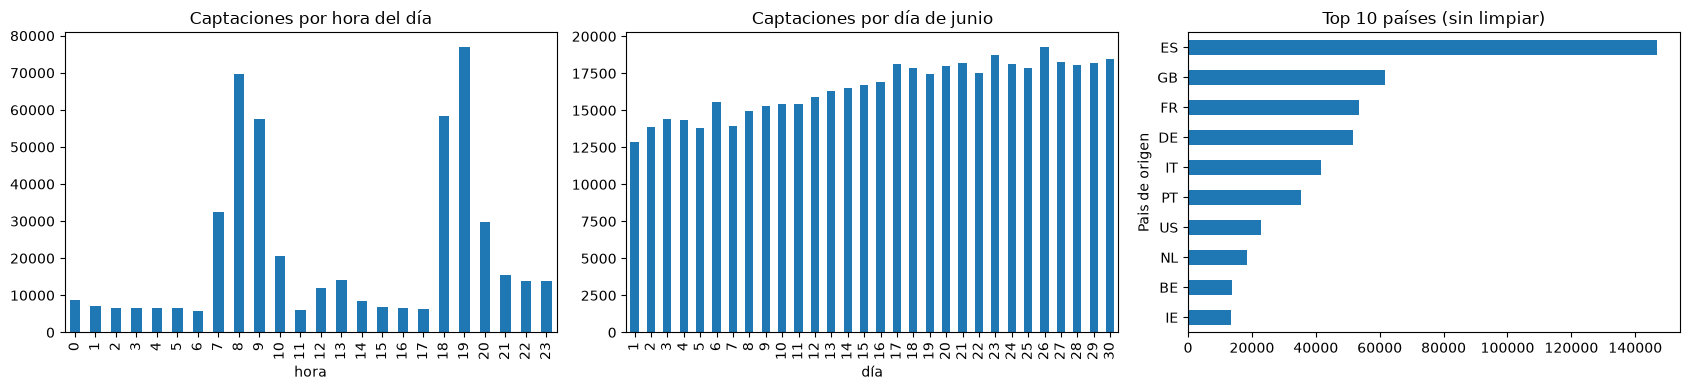

In [5]:
import matplotlib.pyplot as plt

horas = hora_ts.dropna()
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
horas.dt.hour.value_counts().sort_index().plot.bar(ax=ax[0], title="Captaciones por hora del día")
horas.dt.day.value_counts().sort_index().plot.bar(ax=ax[1], title="Captaciones por día de junio")
df["Pais de origen"].value_counts().head(10).plot.barh(ax=ax[2], title="Top 10 países (sin limpiar)")
ax[0].set_xlabel("hora"); ax[1].set_xlabel("día"); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()

**Conclusiones de la exploración**

- Los errores están repartidos de forma pareja por todas las columnas (nulos, vacíos y formatos incorrectos), por lo que ninguna columna queda inutilizable y se pueden descartar las filas dañadas sin sesgar el análisis.
- Hay duplicados exactos que habría que eliminar para no contar dos veces la misma captación.
- La actividad se concentra en dos franjas horarias (mañana y tarde), lo que será clave para decidir en qué momentos mostrar los anuncios.
- La columna "Rango de edad" contiene la edad exacta, por lo que se derivará un rango de edad real como *tag*.

## 2. Limpieza y transformación

**Reglas de validación** (una fila con cualquier campo inválido se descarta):

| Campo | Regla |
|---|---|
| Hora de la captación | Formato `YYYY-MM-DD HH:MM:SS` válido |
| MAC | Seis pares hexadecimales separados por `:` |
| Fabricante / OS / Idioma / País | Debe pertenecer a la lista de valores válidos |
| Nombre | Solo letras y espacios (sin `???`) |
| Edad | Entero entre 15 y 85 |
| Email | `nombre.apellido@dominio` con dominio válido |
| Duplicados | Filas idénticas: se conserva la primera |

**Transformaciones:** `rango_edad` (tag derivado de la edad), hora local → UTC, y desplazamiento de 1 ns cuando dos puntos coinciden en measurement + tags + timestamp (en InfluxDB serían el mismo punto y el segundo sobrescribiría al primero).

In [6]:
FABRICANTES = {"Apple", "Samsung", "Intel", "Lenovo", "HP", "Dell", "ASUS",
               "Xiaomi", "Huawei", "Google", "Sony", "Acer", "Microsoft",
               "Motorola"}
SISTEMAS = {"Android", "iOS", "Windows 11", "Windows 10", "macOS"}
IDIOMAS = {"es-ES", "en-GB", "en-US", "fr-FR", "de-DE", "it-IT", "pt-PT",
           "nl-NL", "pl-PL", "ca-ES", "sv-SE", "es-MX"}
PAISES = {"ES", "GB", "FR", "DE", "IT", "PT", "US", "NL", "IE", "BE", "SE",
          "DK", "PL", "CH", "AT", "MX"}

RE_MAC = r"^(?:[0-9A-F]{2}:){5}[0-9A-F]{2}$"
RE_EMAIL = (r"^[a-z0-9]+\.[a-z0-9]+@"
            r"(?:gmail\.com|hotmail\.com|outlook\.com|yahoo\.com|icloud\.com|proton\.me)$")
RE_NOMBRE = r"^[^\W\d_]+(?:[ '\-][^\W\d_]+)+$"


def limpiar(df):
    """Devuelve (df_limpio, df_rechazado, resumen)."""
    resumen = {"filas_originales": len(df)}

    df = df.copy()
    df.columns = ["hora", "mac", "fabricante", "nombre", "os", "idioma",
                  "edad", "email", "pais"]
    df = df.fillna("").astype(str).apply(lambda c: c.str.strip())

    # 1) Duplicados exactos
    dup = df.duplicated(keep="first")
    resumen["duplicados"] = int(dup.sum())
    df = df[~dup]

    # 2) Validaciones campo a campo
    hora = pd.to_datetime(df["hora"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
    edad = pd.to_numeric(df["edad"], errors="coerce")

    validas = pd.DataFrame({
        "hora": hora.notna(),
        "mac": df["mac"].str.match(RE_MAC),
        "fabricante": df["fabricante"].isin(FABRICANTES),
        "nombre": df["nombre"].str.match(RE_NOMBRE),
        "os": df["os"].isin(SISTEMAS),
        "idioma": df["idioma"].isin(IDIOMAS),
        "edad": edad.between(15, 85) & (edad % 1 == 0),
        "email": df["email"].str.match(RE_EMAIL),
        "pais": df["pais"].isin(PAISES),
    })
    ok = validas.all(axis=1)

    resumen["campos_invalidos"] = {c: int((~validas[c]).sum()) for c in validas.columns}
    rechazado = df[~ok]
    resumen["filas_rechazadas"] = int((~ok).sum())

    # 3) Transformaciones sobre las filas válidas
    limpio = df[ok].copy()
    limpio["hora"] = hora[ok]
    limpio["edad"] = edad[ok].astype(int)
    limpio["rango_edad"] = pd.cut(
        limpio["edad"],
        bins=[14, 24, 34, 44, 54, 64, 85],
        labels=["15-24", "25-34", "35-44", "45-54", "55-64", "65-85"],
    ).astype(str)

    # Hora local -> UTC (InfluxDB guarda siempre en UTC)
    limpio["hora"] = (limpio["hora"]
                      .dt.tz_localize(ZONA_HORARIA, ambiguous="NaT", nonexistent="NaT")
                      .dt.tz_convert("UTC"))
    limpio = limpio.dropna(subset=["hora"])

    # 4) Evitar sobrescrituras: +1 ns por cada repetición de (hora + tags)
    limpio["_n"] = limpio.groupby(["hora"] + TAGS).cumcount()
    resumen["colisiones_resueltas"] = int((limpio["_n"] > 0).sum())
    limpio["hora"] = limpio["hora"] + pd.to_timedelta(limpio["_n"], unit="ns")
    limpio = limpio.drop(columns="_n")

    limpio = limpio.sort_values("hora").set_index("hora")
    limpio = limpio[TAGS + ["mac", "nombre", "email", "edad"]]
    resumen["filas_limpias"] = len(limpio)
    return limpio, rechazado, resumen

In [7]:
limpio, rechazado, r = limpiar(df)
rechazado.to_csv(RECHAZADAS, index=False, encoding="utf-8-sig")

print("=== INFORME DE LIMPIEZA ===")
print(f"Filas originales:        {r['filas_originales']:,}")
print(f"Duplicados eliminados:   {r['duplicados']:,}")
print(f"Filas rechazadas:        {r['filas_rechazadas']:,}  (guardadas en {RECHAZADAS})")
for campo, n in r["campos_invalidos"].items():
    print(f"   - {campo:<11} {n:,}")
print(f"Colisiones resueltas:    {r['colisiones_resueltas']:,}")
print(f"Filas listas para subir: {r['filas_limpias']:,}")
print(f"Rango temporal (UTC):    {limpio.index.min()} -> {limpio.index.max()}")

=== INFORME DE LIMPIEZA ===
Filas originales:        500,000
Duplicados eliminados:   6,419
Filas rechazadas:        31,805  (guardadas en captaciones_rechazadas.csv)
   - hora        3,586
   - mac         3,606
   - fabricante  3,586
   - nombre      3,695
   - os          3,658
   - idioma      3,535
   - edad        3,664
   - email       3,418
   - pais        3,650
Colisiones resueltas:    12,423
Filas listas para subir: 461,776
Rango temporal (UTC):    2026-05-31 22:00:34+00:00 -> 2026-06-30 21:59:56+00:00


### Resultado: datos listos para InfluxDB

El índice es el timestamp (UTC). Las columnas de `TAGS` serán tags y el resto, fields.

In [8]:
display(limpio.head())
print(limpio.dtypes)

,fabricante,os,idioma,pais,rango_edad,mac,nombre,email,edad
hora,,,,,,,,,
2026-05-31 22:00:34+00:00,ASUS,Windows 10,en-GB,US,25-34,00:0C:6E:B5:A3:E9,Enrique Zieliński,enrique.zielinski@hotmail.com,25
2026-05-31 22:04:01+00:00,Apple,macOS,pt-PT,ES,45-54,3C:07:54:90:6D:A1,Charlotte Gómez,charlotte.gomez@proton.me,46
2026-05-31 22:06:42+00:00,Sony,Windows 10,es-ES,ES,15-24,AC:9B:0A:35:64:F9,Eleanor Robinson,eleanor.robinson@hotmail.com,15
2026-05-31 22:07:28+00:00,HP,Windows 10,pt-PT,DE,15-24,64:51:06:AA:1C:F8,Mei Müller,mei.muller@gmail.com,20
2026-05-31 22:10:50+00:00,Google,Android,en-US,FR,15-24,94:EB:CD:5B:63:51,Aisha Weber,aisha.weber@hotmail.com,15


fabricante      str
os              str
idioma          str
pais            str
rango_edad      str
mac             str
nombre          str
email           str
edad          int64
dtype: object


In [9]:
# Distribución de los tags (útil para comprobar que la limpieza no ha sesgado los datos)
for tag in TAGS:
    print(f"--- {tag} ---")
    print(limpio[tag].value_counts().head(8).to_string(), "\n")

--- fabricante ---
fabricante
Apple      83774
Samsung    73840
Intel      68326
Lenovo     42045
HP         36996
Dell       31550
ASUS       28965
Xiaomi     22327 

--- os ---
os
Windows 11    180930
Android       107293
Windows 10     89779
iOS            69835
macOS          13939 

--- idioma ---
idioma
es-ES    111134
en-GB     73365
en-US     62937
fr-FR     47607
de-DE     41893
it-IT     35948
pt-PT     24716
nl-NL     18721 

--- pais ---
pais
ES    136462
GB     57318
FR     49774
DE     47948
IT     38685
PT     32961
US     21124
NL     17172 

--- rango_edad ---
rango_edad
25-34    124370
15-24    108862
35-44    104318
45-54     75372
55-64     38109
65-85     10745 



## 3. Subida a InfluxDB 2.x

Requisitos previos:
- Bucket `captaciones_julio` creado, con retención *Never*.
- Token de escritura de pandas: `export INFLUX_TOKEN='...'` antes de arrancar Jupyter (o definirlo en la celda de configuración).
- `pip install influxdb-client`

Cambia `SUBIR = True` para ejecutar la carga real.

In [10]:
SUBIR = True


def subir(df):
    from influxdb_client import InfluxDBClient, WriteOptions

    if not INFLUX_TOKEN:
        raise RuntimeError("Falta INFLUX_TOKEN")

    with InfluxDBClient(url=INFLUX_URL, token=INFLUX_TOKEN,
                        org=INFLUX_ORG, timeout=60_000) as client:
        write_api = client.write_api(write_options=WriteOptions(
            batch_size=TAMANO_LOTE, flush_interval=5_000))
        for i in range(0, len(df), TAMANO_LOTE):
            lote = df.iloc[i:i + TAMANO_LOTE]
            write_api.write(
                bucket=INFLUX_BUCKET,
                record=lote,
                data_frame_measurement_name=MEASUREMENT,
                data_frame_tag_columns=TAGS,
            )
            print(f"  subidas {min(i + TAMANO_LOTE, len(df)):,} / {len(df):,}")
        write_api.close()


if SUBIR:
    print(f"Subiendo a {INFLUX_URL}  bucket={INFLUX_BUCKET} ...")
    subir(limpio)
    print("Carga completada.")
else:
    print("Subida desactivada (SUBIR = False). Nada se ha enviado a InfluxDB.")

Subiendo a http://localhost:8086  bucket=captaciones_julio ...
  subidas 10,000 / 461,776
  subidas 20,000 / 461,776
  subidas 30,000 / 461,776
  subidas 40,000 / 461,776
  subidas 50,000 / 461,776
  subidas 60,000 / 461,776
  subidas 70,000 / 461,776
  subidas 80,000 / 461,776
  subidas 90,000 / 461,776
  subidas 100,000 / 461,776
  subidas 110,000 / 461,776
  subidas 120,000 / 461,776
  subidas 130,000 / 461,776
  subidas 140,000 / 461,776
  subidas 150,000 / 461,776
  subidas 160,000 / 461,776
  subidas 170,000 / 461,776
  subidas 180,000 / 461,776
  subidas 190,000 / 461,776
  subidas 200,000 / 461,776
  subidas 210,000 / 461,776
  subidas 220,000 / 461,776
  subidas 230,000 / 461,776
  subidas 240,000 / 461,776
  subidas 250,000 / 461,776
  subidas 260,000 / 461,776
  subidas 270,000 / 461,776
  subidas 280,000 / 461,776
  subidas 290,000 / 461,776
  subidas 300,000 / 461,776
  subidas 310,000 / 461,776
  subidas 320,000 / 461,776
  subidas 330,000 / 461,776
  subidas 340,000 / 46

## 4. Verificación en InfluxDB

En la *Data Explorer* (Script Editor) de InfluxDB, esta consulta debe devolver el mismo número que `filas_limpias`:

```flux
from(bucket: "captaciones_julio")
  |> range(start: 2026-05-31T00:00:00Z, stop: 2026-07-01T00:00:00Z)
  |> filter(fn: (r) => r._measurement == "captaciones" and r._field == "edad")
  |> count()
  |> group()
  |> sum()
```